In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0
GPU available: []


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28) | Test: (10000, 28, 28)


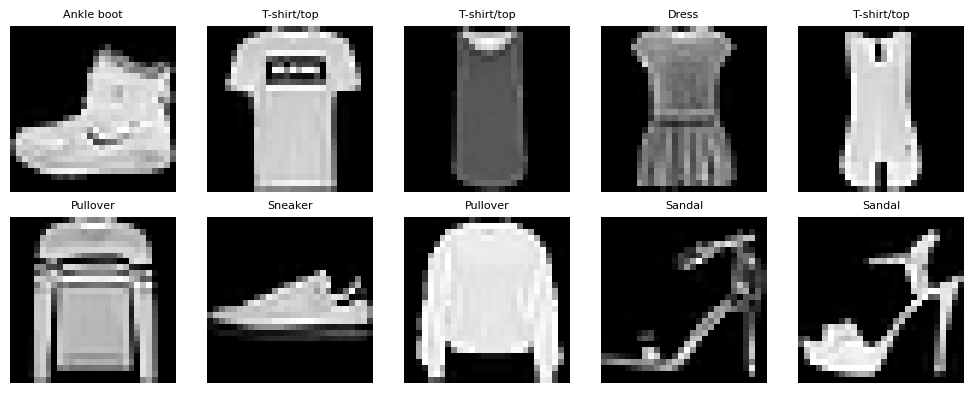

In [2]:
# 70,000 images of clothing, 10 classes, 28x28 grayscale
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat',
               'Sandal','Shirt','Sneaker','Bag','Ankle boot']

print("Train:", x_train.shape, "| Test:", x_test.shape)

# Quick peek
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis('off')
plt.tight_layout(); plt.show()

In [3]:
# Normalize + add channel dim  → (N, 28, 28, 1)
x_train = (x_train.astype('float32') / 255.0)[..., np.newaxis]
x_test  = (x_test.astype('float32')  / 255.0)[..., np.newaxis]

# Validation split
x_val, y_val = x_train[:5000], y_train[:5000]
x_tr,  y_tr  = x_train[5000:], y_train[5000:]

print(x_tr.shape, x_val.shape, x_test.shape)

(55000, 28, 28, 1) (5000, 28, 28, 1) (10000, 28, 28, 1)


In [4]:
def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28,28,1)),

        tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Dropout(0.25),

        tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Dropout(0.25),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                     patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                         factor=0.5, patience=2, min_lr=1e-5),
]

history = model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f}")

Epoch 1/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 72s 160ms/step - accuracy: 0.7721 - loss: 0.6257 - val_accuracy: 0.8714 - val_loss: 0.3671 - learning_rate: 0.0010
Epoch 2/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 82s 162ms/step - accuracy: 0.8541 - loss: 0.4056 - val_accuracy: 0.8896 - val_loss: 0.3173 - learning_rate: 0.0010
Epoch 3/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 82s 161ms/step - accuracy: 0.8715 - loss: 0.3548 - val_accuracy: 0.8996 - val_loss: 0.2852 - learning_rate: 0.0010
Epoch 4/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 82s 160ms/step - accuracy: 0.8801 - loss: 0.3276 - val_accuracy: 0.9010 - val_loss: 0.2706 - learning_rate: 0.0010
Epoch 5/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 68s 159ms/step - accuracy: 0.8900 - loss: 0.3048 - val_accuracy: 0.9062 - val_loss: 0.2558 - learning_rate: 0.0010
Epoch 6/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 83s 161ms/step - accuracy: 0.8938 - loss: 0.2892 - val_accuracy: 0.9108 - val_loss: 0.2439 - learning_rate: 0.0010
Epoch 7/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 68s 157ms/step - accuracy: 0.8

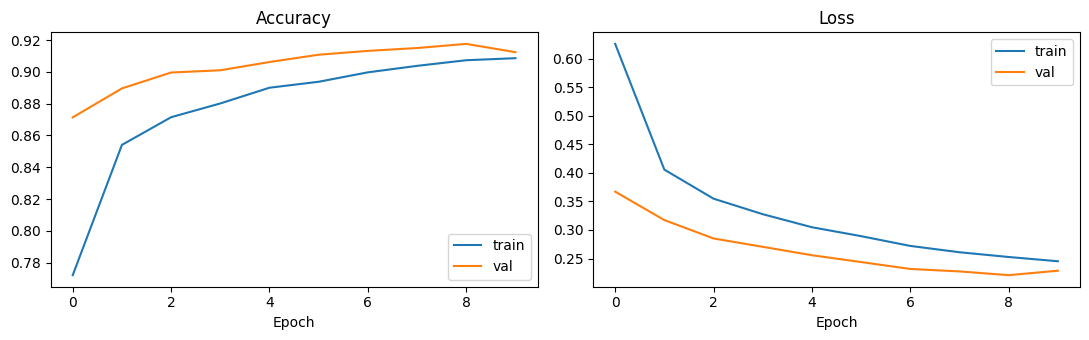

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11,3.5))

ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='val')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='val')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()

plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

 T-shirt/top       0.82      0.90      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.84      0.90      0.87      1000
       Dress       0.92      0.90      0.91      1000
        Coat       0.82      0.88      0.85      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.80      0.64      0.71      1000
     Sneaker       0.95      0.99      0.97      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



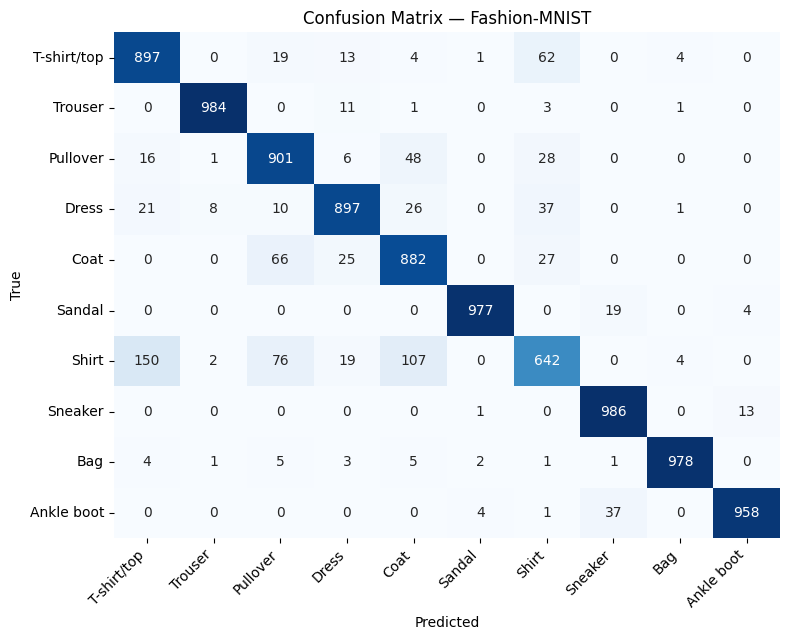

In [7]:
y_pred = np.argmax(model.predict(x_test, batch_size=256, verbose=0), axis=1)

print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xticks(rotation=45, ha='right')
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix — Fashion-MNIST")
plt.tight_layout(); plt.show()

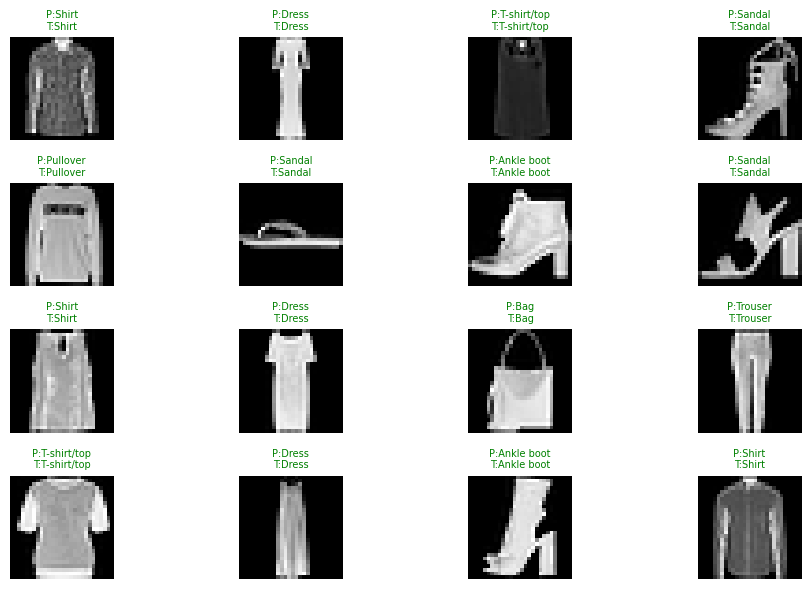

In [8]:
idx = np.random.choice(len(x_test), 16, replace=False)
probs = model.predict(x_test[idx], verbose=0)
preds = np.argmax(probs, axis=1)

plt.figure(figsize=(10,6))
for i, k in enumerate(idx):
    plt.subplot(4,4,i+1)
    plt.imshow(x_test[k].squeeze(), cmap='gray')
    color = 'green' if preds[i]==y_test[k] else 'red'
    plt.title(f"P:{class_names[preds[i]]}\nT:{class_names[y_test[k]]}",
              color=color, fontsize=7)
    plt.axis('off')
plt.tight_layout(); plt.show()

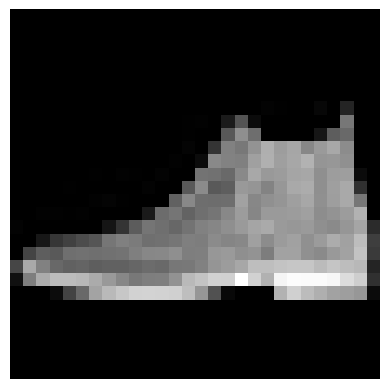

  Ankle boot    99.75%
  Sneaker        0.25%
  Sandal         0.00%


In [9]:
model.save("fashion_cnn.keras")
loaded = tf.keras.models.load_model("fashion_cnn.keras")

def predict(img):
    """img: (28,28) or (28,28,1) float in [0,1]"""
    x = np.array(img).reshape(1,28,28,1)
    p = loaded.predict(x, verbose=0)[0]
    order = np.argsort(p)[::-1][:3]
    for i in order:
        print(f"  {class_names[i]:12s}  {p[i]*100:5.2f}%")

# Demo
plt.imshow(x_test[0].squeeze(), cmap='gray'); plt.axis('off'); plt.show()
predict(x_test[0])